In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
!pip install -q diffusers transformers accelerate safetensors

In [3]:
import torch
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    use_safetensors=True
)

pipe = pipe.to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

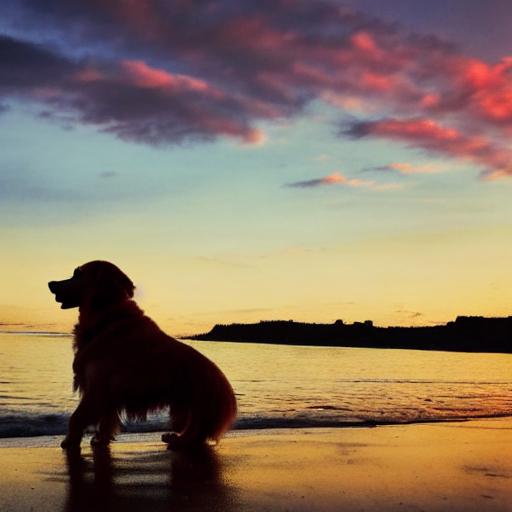

In [4]:
prompt = "A cute golden retriever sitting on a beach at sunset, realistic photography"

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

display(image)

In [5]:
image.save("first_generated_image.png")

In [6]:
from google.colab import files

files.download("first_generated_image.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
!pip install -q fastapi uvicorn pyngrok

In [8]:
from pyngrok import ngrok

ngrok.set_auth_token("3KDfCKn1fF3eJW5KQwcQloyOqx9_5ZCLcoZNusTchzRxnPQKE")

In [9]:
public_url = ngrok.connect(8000)

print("Public URL:", public_url)

Public URL: NgrokTunnel: "https://disarray-overeager-junction.ngrok-free.dev" -> "http://localhost:8000"


In [10]:
print(public_url.public_url)

https://disarray-overeager-junction.ngrok-free.dev


In [11]:
import requests

response = requests.post(
    public_url.public_url + "/generate",
    json={"prompt": "a cute dog sitting on a beach"}
)

print("Status code:", response.status_code)
print(response.text[:200])

Status code: 404
<!DOCTYPE html>
<html class="h-full" lang="en-US" dir="ltr">
  <head>
    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <link rel="preload" href="


In [12]:
import base64
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

data = response.json()

image_bytes = base64.b64decode(data["image"])

image = Image.open(BytesIO(image_bytes))

display(image)

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [ ]:
from fastapi import FastAPI
from pydantic import BaseModel
import io
import base64

app = FastAPI()


class PromptRequest(BaseModel):
    prompt: str


@app.post("/generate")
def generate(request: PromptRequest):

    # Generate image using Stable Diffusion
    image = pipe(
        request.prompt,
        num_inference_steps=25,
        guidance_scale=7.5
    ).images[0]

    # Convert image to PNG bytes
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")

    # Convert image to Base64
    image_base64 = base64.b64encode(
        buffer.getvalue()
    ).decode("utf-8")

    return {
        "image": image_base64
    }

In [ ]:
import threading
import uvicorn


def run_server():
    uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000
    )


thread = threading.Thread(
    target=run_server,
    daemon=True
)

thread.start()